Dưới đây là toàn bộ nội dung và cấu trúc mã nguồn hoàn chỉnh của Notebook `01_ecommerce_recommender_pipeline.ipynb` chạy trên Google Colab.

Notebook được chia thành các cell tuần tự, tích hợp hướng dẫn chi tiết tạo và nạp Secret Key cho từng tác vụ, ETL streaming chống tràn RAM, 6 kỹ thuật trực quan hóa, huấn luyện Hybrid Recommender (Cosine Similarity + TruncatedSVD), tự động đẩy Dataset & Model Artifacts lên Hugging Face Hub bằng `HF_WRITE_MODELS_TOKEN`, và đẩy lên Azure (Blob Storage & Cosmos DB) với cơ chế fallback an toàn nếu chưa cấu hình tài nguyên Cloud.

---

# HƯỚNG DẪN CẤU HÌNH SECRET KEYS TRÊN GOOGLE COLAB

Trước khi thực thi các cell, mở thanh menu bên trái của Google Colab:

1. Nhấp vào biểu tượng chiếc chìa khóa (**Secrets** / Khóa bí mật).
2. Thêm các Secret Key sau bằng cách bấm **Add new secret** và bật quyền truy cập (**Notebook access**):

| Tên Secret Key (`Name`) | Giá trị (`Value`) | Mục đích & Cách lấy |
| --- | --- | --- |
| `HF_WRITE_MODELS_TOKEN` | `hf_xxxx...` *(Đã có)* | Token có quyền **Write** trên Hugging Face. Lấy tại: `huggingface.co/settings/tokens` (Role: `Write`). Dùng để đẩy Dataset sạch và Model Artifacts lên HF Hub. |
| `HF_USERNAME` | `<username_hf>` | Username tài khoản Hugging Face của bạn để tạo repository (ví dụ: `cuongdev`). |
| `AZURE_STORAGE_CONNECTION_STRING` | `DefaultEndpointsProtocol=https;...` | *(Tùy chọn)* Kết nối Azure Blob Storage. Cách lấy: Vào **Azure Portal** $\rightarrow$ **Storage accounts** $\rightarrow$ Chọn account $\rightarrow$ Menu **Security + networking** $\rightarrow$ **Access keys** $\rightarrow$ Copy **Connection string** của `key1`. |
| `COSMOS_DB_ENDPOINT` | `https://<account>[.documents.azure.com:443/](https://.documents.azure.com:443/)` | *(Tùy chọn)* Endpoint Azure Cosmos DB NoSQL. Cách lấy: Vào **Azure Portal** $\rightarrow$ **Azure Cosmos DB** $\rightarrow$ Chọn account $\rightarrow$ Menu **Keys** $\rightarrow$ Copy trường **URI**. |
| `COSMOS_DB_PRIMARY_KEY` | `<master_key>==` | *(Tùy chọn)* Khóa truy cập Cosmos DB. Cách lấy: Cùng trang **Keys** với URI $\rightarrow$ Copy trường **PRIMARY KEY**. |

---


Dưới đây là toàn bộ nội dung và cấu trúc mã nguồn hoàn chỉnh của Notebook `01_ecommerce_recommender_pipeline.ipynb` chạy trên Google Colab.

Notebook được chia thành các cell tuần tự, tích hợp hướng dẫn chi tiết tạo và nạp Secret Key cho từng tác vụ, ETL streaming chống tràn RAM, 6 kỹ thuật trực quan hóa, huấn luyện Hybrid Recommender (Cosine Similarity + TruncatedSVD), tự động đẩy Dataset & Model Artifacts lên Hugging Face Hub bằng `HF_WRITE_MODELS_TOKEN`, và đẩy lên Azure (Blob Storage & Cosmos DB) với cơ chế fallback an toàn nếu chưa cấu hình tài nguyên Cloud.

---

# HƯỚNG DẪN CẤU HÌNH SECRET KEYS TRÊN GOOGLE COLAB

Trước khi thực thi các cell, mở thanh menu bên trái của Google Colab:

1. Nhấp vào biểu tượng chiếc chìa khóa (**Secrets** / Khóa bí mật).
2. Thêm các Secret Key sau bằng cách bấm **Add new secret** và bật quyền truy cập (**Notebook access**):

| Tên Secret Key (`Name`) | Giá trị (`Value`) | Mục đích & Cách lấy |
| --- | --- | --- |
| `HF_WRITE_MODELS_TOKEN` | `hf_xxxx...` *(Đã có)* | Token có quyền **Write** trên Hugging Face. Lấy tại: `huggingface.co/settings/tokens` (Role: `Write`). Dùng để đẩy Dataset sạch và Model Artifacts lên HF Hub. |
| `HF_USERNAME` | `<username_hf>` | Username tài khoản Hugging Face của bạn để tạo repository (ví dụ: `cuongdev`). |
| `AZURE_STORAGE_CONNECTION_STRING` | `DefaultEndpointsProtocol=https;...` | *(Tùy chọn)* Kết nối Azure Blob Storage. Cách lấy: Vào **Azure Portal** $\rightarrow$ **Storage accounts** $\rightarrow$ Chọn account $\rightarrow$ Menu **Security + networking** $\rightarrow$ **Access keys** $\rightarrow$ Copy **Connection string** của `key1`. |
| `COSMOS_DB_ENDPOINT` | `https://<account>[.documents.azure.com:443/](https://.documents.azure.com:443/)` | *(Tùy chọn)* Endpoint Azure Cosmos DB NoSQL. Cách lấy: Vào **Azure Portal** $\rightarrow$ **Azure Cosmos DB** $\rightarrow$ Chọn account $\rightarrow$ Menu **Keys** $\rightarrow$ Copy trường **URI**. |
| `COSMOS_DB_PRIMARY_KEY` | `<master_key>==` | *(Tùy chọn)* Khóa truy cập Cosmos DB. Cách lấy: Cùng trang **Keys** với URI $\rightarrow$ Copy trường **PRIMARY KEY**. |

---

# CẤU TRÚC CHI TIẾT CÁC CELL TRONG NOTEBOOK

### Cell 1 [Code]: Cài đặt các thư viện cần thiết


In [1]:
# [Cell 1] Cài đặt dependencies cho Data Processing, ML, Hugging Face Hub & Azure SDK
!pip install -q datasets huggingface_hub scikit-learn pandas numpy scipy matplotlib seaborn
!pip install -q azure-storage-blob azure-cosmos python-dotenv
print("✅ Hoàn tất cài đặt các thư viện phụ thuộc.")

✅ Hoàn tất cài đặt các thư viện phụ thuộc.



### Cell 2 [Code]: Nạp Secret Keys và Khởi tạo Cấu hình

In [2]:
# [Cell 2] Nạp Secret Keys an toàn từ Google Colab Secrets và định nghĩa tham số hệ thống
import os
import json
import numpy as np
import pandas as pd
from google.colab import userdata

# 1. Hugging Face Credentials
try:
    HF_TOKEN = userdata.get('HF_WRITE_MODELS_TOKEN')
    print("🔑 Đã nạp thành công HF_WRITE_MODELS_TOKEN từ Colab Secrets.")
except Exception:
    HF_TOKEN = os.getenv("HF_WRITE_MODELS_TOKEN", None)
    if not HF_TOKEN:
        print("⚠️ Chưa tìm thấy HF_WRITE_MODELS_TOKEN trong Secrets. Hãy thêm vào Colab Secrets.")

try:
    HF_USERNAME = userdata.get('HF_USERNAME')
except Exception:
    HF_USERNAME = os.getenv("HF_USERNAME", "my-ecommerce-recommender")

# 2. Azure Credentials (Tùy chọn - nếu chưa có sẽ chạy ở chế độ Local Mock/Dry-run)
try:
    AZURE_STORAGE_CONN_STR = userdata.get('AZURE_STORAGE_CONNECTION_STRING')
    print("🔑 Đã nạp AZURE_STORAGE_CONNECTION_STRING.")
except Exception:
    AZURE_STORAGE_CONN_STR = os.getenv("AZURE_STORAGE_CONNECTION_STRING", None)

try:
    COSMOS_ENDPOINT = userdata.get('COSMOS_DB_ENDPOINT')
    COSMOS_KEY = userdata.get('COSMOS_DB_PRIMARY_KEY')
    print("🔑 Đã nạp cấu hình Azure Cosmos DB.")
except Exception:
    COSMOS_ENDPOINT = os.getenv("COSMOS_DB_ENDPOINT", None)
    COSMOS_KEY = os.getenv("COSMOS_DB_PRIMARY_KEY", None)

# 3. Định nghĩa thư mục lưu trữ cục bộ
DIRS = ["data/raw", "data/processed", "models", "exports"]
for d in DIRS:
    os.makedirs(d, exist_ok=True)

# 4. Siêu tham số
TARGET_CATEGORY = "Musical_Instruments"
NUM_PRODUCTS = 1000
NUM_INTERACTIONS = 5000
SVD_FACTORS = 20
RANDOM_STATE = 42

print(f"⚙️ Target: {NUM_PRODUCTS} products, {NUM_INTERACTIONS} interactions. SVD k={SVD_FACTORS}")

🔑 Đã nạp thành công HF_WRITE_MODELS_TOKEN từ Colab Secrets.
🔑 Đã nạp AZURE_STORAGE_CONNECTION_STRING.
🔑 Đã nạp cấu hình Azure Cosmos DB.
⚙️ Target: 1000 products, 5000 interactions. SVD k=20


### Cell 3 [Code]: ETL Pipeline - Streaming dữ liệu từ Hugging Face & Tiền xử lý
### 1. Phân tích các phương pháp lọc hiện tại trong code

Trong script cũ của bạn, pipeline đang áp dụng các kỹ thuật lọc sau:

* **Heuristic Filtering (Lọc thuộc tính rỗng):** Bỏ qua các item thiếu `parent_asin`, `title`, hoặc mảng `images` rỗng (`if not p_id or not title or not images`).
* **Data Cleaning & Type Casting:** Ép kiểu rating thành `float`, bóc tách ký tự số từ chuỗi `price` (loại bỏ `$`, dấu phẩy), điền giá trị thiếu (imputation) bằng giá trị trung vị (`median`).
* **Candidate Matching (Lọc khớp ban đầu):** Khi đọc reviews, chỉ lấy review thuộc tập `candidate_pids` đang có trong `df_meta_pool`.
* **User-Side K-Core (Core threshold = 2):** Lọc người dùng có ít nhất 2 đánh giá (`active_users >= 2`) để giảm độ thưa (sparsity) của ma trận tương tác.
* **Frequency-based Selection:** Chọn top `NUM_PRODUCTS` có số lượt đánh giá cao nhất từ tập user hợp lệ, fallback bù thêm nếu thiếu.
* **Strict Item-Interaction Alignment:** Lọc bảng tương tác sao cho chỉ giữ lại interaction thuộc danh sách `df_clean_products` đã chốt, sau đó ưu tiên `verified_purchase == True` và sắp xếp theo mốc thời gian mới nhất.

---

### 2. Những nâng cấp trong code mới

1. **Async Image Validation (`aiohttp` + `asyncio`):**
* Sử dụng `HEAD` request (fallback `GET` với `stream/read chunk` nhỏ nếu gặp `405 Method Not Allowed`).
* Sử dụng `asyncio.Semaphore(50)` để giới hạn số lượng kết nối đồng thời, tránh bị CDN Amazon chặn IP/rate limit hoặc nghẽn socket máy tính.
* **Chiến thuật tối ưu:** Chỉ kiểm tra ảnh trên tập sản phẩm sau khi đã chọn lọc ban đầu (không quét trên toàn bộ streaming pool), tiết kiệm thời gian từ vài phút xuống còn vài giây.


2. **Loại bỏ triệt để tương tác mồ côi (Dangling Interactions):**
* Sản phẩm bị rớt do link ảnh hỏng sẽ bị loại.
* Tập tương tác cuối cùng được lọc bằng `isin(df_clean_products["product_id"])` và loại bỏ hoàn toàn các interaction của sản phẩm không tồn tại trong hệ thống.


3. **Phân tách 2 phiên bản Dataset:**
* **Bản Web/Database:** Gọn nhẹ, chỉ chứa các trường cần hiển thị UI và nạp DB (`product_id`, `name`, `category`, `price`, `thumbnail_url`, `description`, `rating`, `rating_count`, `stock_quantity`).
* **Bản Training:** Đầy đủ các trường phục vụ huấn luyện (NLP embeddings, Graph, Collaborative Filtering) như `content_raw`, `features`, `bought_together`, `verified_purchase`, `timestamp`, `user_id`.



---

#### [Cell 3] Toàn bộ code nâng cấp

In [12]:
# [Cell 3] ETL Pipeline: Async Image Validation, Strict Interaction Filtering & Multi-tier Exports
import re
import os
import asyncio
import aiohttp
import pandas as pd
from datasets import load_dataset

# Cấu hình biến mặc định nếu chưa định nghĩa ở Cell trước
TARGET_CATEGORY = globals().get("TARGET_CATEGORY", "All_Beauty")
NUM_PRODUCTS = globals().get("NUM_PRODUCTS", 1000)
NUM_INTERACTIONS = globals().get("NUM_INTERACTIONS", 5000)
os.makedirs("data/processed", exist_ok=True)

# -------------------------------------------------------------------------
# 1. BỘ KIỂM TRA LINK ẢNH BẤT ĐỒNG BỘ (ASYNC VALIDATOR)
# -------------------------------------------------------------------------
async def check_image_url(session: aiohttp.ClientSession, url: str, semaphore: asyncio.Semaphore) -> bool:
    """Gửi HEAD/GET request bất đồng bộ kiểm tra link ảnh còn sống hay không."""
    if not url or not isinstance(url, str) or not url.startswith(("http://", "https://")):
        return False

    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
    }

    async with semaphore:
        try:
            # Thử HEAD request trước để tiết kiệm bandwidth
            async with session.head(url, headers=headers, timeout=aiohttp.ClientTimeout(total=4), allow_redirects=True) as resp:
                if resp.status == 200 and "image" in resp.headers.get("Content-Type", "").lower():
                    return True
                # Một số CDN Amazon chặn HEAD (trả 405/403), thử lại với GET chỉ đọc 1 byte
                if resp.status in (403, 405):
                    async with session.get(url, headers=headers, timeout=aiohttp.ClientTimeout(total=4), allow_redirects=True) as get_resp:
                        if get_resp.status == 200 and "image" in get_resp.headers.get("Content-Type", "").lower():
                            return True
            return False
        except Exception:
            return False

async def batch_verify_images(urls: list, max_concurrent: int = 50) -> list:
    """Quét đồng thời danh sách URL bằng Asyncio Semaphore."""
    semaphore = asyncio.Semaphore(max_concurrent)
    connector = aiohttp.TCPConnector(limit=max_concurrent, ssl=False)

    async with aiohttp.ClientSession(connector=connector) as session:
        tasks = [check_image_url(session, u, semaphore) for u in urls]
        return await asyncio.gather(*tasks)

# Hỗ trợ chạy async trên cả môi trường Jupyter Notebook và script Python thông thường
def run_async_validation(urls: list):
    try:
        loop = asyncio.get_running_loop()
        import nest_asyncio
        nest_asyncio.apply()
        return loop.run_until_complete(batch_verify_images(urls))
    except RuntimeError:
        return asyncio.run(batch_verify_images(urls))

# -------------------------------------------------------------------------
# 2. STREAMING & TRÍCH XUẤT SẢN PHẨM (METADATA)
# -------------------------------------------------------------------------
print(f"⏳ [1/5] Đang streaming Metadata ({TARGET_CATEGORY}) từ Hugging Face...")
meta_stream = load_dataset(
    "McAuley-Lab/Amazon-Reviews-2023",
    f"raw_meta_{TARGET_CATEGORY}",
    split="full",
    streaming=True
)

raw_products = []
POOL_LIMIT = max(NUM_PRODUCTS * 3, 3000)

for item in meta_stream:
    p_id = item.get("parent_asin")
    title = item.get("title")
    images = item.get("images", [])

    # Lọc rác cấp 1: Thiếu id, tên hoặc mảng ảnh rỗng
    if not p_id or not title or not images:
        continue

    # Bóc tách thumbnail URL
    thumb_url = ""
    if isinstance(images, list) and len(images) > 0:
        first_img = images[0]
        thumb_url = first_img.get("large", "") if isinstance(first_img, dict) else str(first_img)
    if not thumb_url:
        continue

    # Xử lý giá bán
    price_val = item.get("price")
    try:
        if isinstance(price_val, (int, float)):
            price = float(price_val)
        elif isinstance(price_val, str):
            clean_p = re.sub(r"[^\d.]", "", price_val)
            price = float(clean_p) if clean_p else None
        else:
            price = None
    except Exception:
        price = None

    categories = item.get("categories", [])
    sub_category = categories[-1] if len(categories) > 0 else TARGET_CATEGORY

    desc_list = item.get("description", [])
    desc_text = " ".join(desc_list) if isinstance(desc_list, list) else str(desc_list or "")
    features_list = item.get("features", [])
    feat_text = " ".join(features_list) if isinstance(features_list, list) else ""

    content_raw = f"{title} {feat_text} {sub_category}".strip()
    bought_together = item.get("bought_together", []) or []

    raw_products.append({
        "product_id": p_id,
        "name": title.strip()[:200],
        "category": sub_category,
        "price": price,
        "thumbnail_url": thumb_url,
        "description": desc_text[:500],
        "features": feat_text,
        "rating": float(item.get("average_rating", 0.0) or 0.0),
        "rating_count": int(item.get("rating_number", 0) or 0),
        "stock_quantity": 100,
        "content_raw": content_raw,
        "bought_together": bought_together
    })

    if len(raw_products) >= POOL_LIMIT:
        break

df_meta_pool = pd.DataFrame(raw_products).drop_duplicates(subset=["product_id"])

# Impute giá thiếu bằng median
median_price = df_meta_pool["price"].dropna().median()
if pd.isna(median_price):
    median_price = 19.99
df_meta_pool["price"] = df_meta_pool["price"].fillna(median_price).round(2)
print(f"📦 Đã thu thập {len(df_meta_pool)} sản phẩm ứng viên ban đầu.")

# -------------------------------------------------------------------------
# 3. STREAMING & TRÍCH XUẤT TƯƠNG TÁC (REVIEWS)
# -------------------------------------------------------------------------
print(f"⏳ [2/5] Đang streaming Lịch sử Đánh giá...")
review_stream = load_dataset(
    "McAuley-Lab/Amazon-Reviews-2023",
    f"raw_review_{TARGET_CATEGORY}",
    split="full",
    streaming=True
)

raw_reviews = []
candidate_pids = set(df_meta_pool["product_id"])
REVIEW_POOL_LIMIT = max(NUM_INTERACTIONS * 6, 30000)

for rev in review_stream:
    pid = rev.get("parent_asin")
    uid = rev.get("user_id")
    rating = rev.get("rating")

    # Chỉ lưu các review thuộc sản phẩm có trong candidate pool
    if pid in candidate_pids and uid and rating is not None:
        try:
            rating_val = float(rating)
        except Exception:
            continue

        raw_reviews.append({
            "user_id": uid,
            "product_id": pid,
            "rating": rating_val,
            "timestamp": int(rev.get("timestamp", 0) or 0),
            "verified_purchase": bool(rev.get("verified_purchase", False))
        })

    if len(raw_reviews) >= REVIEW_POOL_LIMIT:
        break

df_reviews_pool = pd.DataFrame(raw_reviews)
print(f"💬 Đã thu thập {len(df_reviews_pool)} tương tác thô ban đầu.")

# -------------------------------------------------------------------------
# 4. LỌC K-CORE & KIỂM TRA SỐNG CỦA ẢNH BẰNG ASYNC
# -------------------------------------------------------------------------
print("⏳ [3/5] Chọn lọc sản phẩm & Xác thực link ảnh bất đồng bộ...")
active_users = df_reviews_pool["user_id"].value_counts()
valid_users = active_users[active_users >= 2].index
df_filtered = df_reviews_pool[df_reviews_pool["user_id"].isin(valid_users)]

# Ưu tiên các sản phẩm có nhiều tương tác nhất
top_items = df_filtered["product_id"].value_counts().index.tolist()
all_pids_sorted = top_items + [p for p in df_meta_pool["product_id"] if p not in top_items]

# Lấy dôi ra 20% ứng viên để dự phòng link ảnh chết
test_candidates = all_pids_sorted[: int(NUM_PRODUCTS * 1.25)]
df_candidates = df_meta_pool[df_meta_pool["product_id"].isin(test_candidates)].copy()

print(f"🌐 Đang ping bất đồng bộ {len(df_candidates)} ảnh sản phẩm...")
valid_mask = run_async_validation(df_candidates["thumbnail_url"].tolist())
df_candidates["is_live"] = valid_mask

# Chỉ giữ các sản phẩm có ảnh sống thực tế
df_alive_products = df_candidates[df_candidates["is_live"]].copy()
print(f"🖼️ Ảnh truy cập tốt: {len(df_alive_products)}/{len(df_candidates)}")

# Chốt đúng số lượng sản phẩm NUM_PRODUCTS
df_clean_products = df_alive_products.head(NUM_PRODUCTS).reset_index(drop=True)
selected_product_ids = set(df_clean_products["product_id"])

# -------------------------------------------------------------------------
# 5. LỌC TƯƠNG TÁC NGHIÊM NGẶT (CHỈ GIỮ SẢN PHẨM ĐÃ CHỌN)
# -------------------------------------------------------------------------
print("⏳ [4/5] Lọc tương tác theo danh sách sản phẩm hợp lệ...")

# LOẠI BỎ TOÀN BỘ tương tác với sản phẩm KHÔNG ĐƯỢC CHỌN
df_clean_interactions = df_reviews_pool[
    df_reviews_pool["product_id"].isin(selected_product_ids)
].copy()

# Ưu tiên verified_purchase và timestamp gần nhất
if len(df_clean_interactions) > NUM_INTERACTIONS:
    df_clean_interactions = df_clean_interactions.sort_values(
        by=["verified_purchase", "timestamp"], ascending=[False, False]
    ).head(NUM_INTERACTIONS)
else:
    df_clean_interactions = df_clean_interactions.sort_values(
        by=["timestamp"], ascending=[False]
    )

df_clean_interactions = df_clean_interactions.reset_index(drop=True)

# Kiểm tra lại tính toàn vẹn (không có foreign key mồ côi)
assert df_clean_interactions["product_id"].isin(selected_product_ids).all(), "Lỗi: Vẫn còn tương tác của sản phẩm nằm ngoài hệ thống!"

print(f"\n📊 Kết quả chuẩn hóa:")
print(f"   • Sản phẩm hợp lệ (ảnh sống 100%): {len(df_clean_products)}")
print(f"   • Tương tác hợp lệ (khớp hoàn toàn SP): {len(df_clean_interactions)}")
print(f"   • User duy nhất: {df_clean_interactions['user_id'].nunique()}")

# -------------------------------------------------------------------------
# 6. LƯU THEO 2 PHIÊN BẢN (WEB SERVING & MODEL TRAINING)
# -------------------------------------------------------------------------
print("⏳ [5/5] Đang xuất dữ liệu ra các file theo mục đích sử dụng...")

# Bản 1: Dành cho Web Application / PostgreSQL (Tối giản, nhẹ)
web_product_cols = [
    "product_id", "name", "category", "price",
    "thumbnail_url", "description", "rating",
    "rating_count", "stock_quantity"
]
df_web_products = df_clean_products[web_product_cols].copy()

# Bản 2: Dành cho Training Machine Learning / GNN / RecSys (Đầy đủ features)
df_training_products = df_clean_products.copy()
df_training_interactions = df_clean_interactions.copy()

# Xuất Parquet
df_web_products.to_parquet("data/processed/web_products.parquet", index=False)
df_training_products.to_parquet("data/processed/training_products.parquet", index=False)
df_training_interactions.to_parquet("data/processed/training_interactions.parquet", index=False)

# Tạo script SQL Seed cho PostgreSQL từ bản Web
sql_statements = [
    "CREATE TABLE IF NOT EXISTS products (",
    "    id VARCHAR(50) PRIMARY KEY,",
    "    name VARCHAR(255) NOT NULL,",
    "    category VARCHAR(100),",
    "    price NUMERIC(10, 2),",
    "    image_url TEXT,",
    "    stock_quantity INT DEFAULT 100,",
    "    description TEXT",
    ");\n"
]

for _, r in df_web_products.iterrows():
    p_id = str(r["product_id"]).replace("'", "''")
    p_name = str(r["name"]).replace("'", "''")
    p_cat = str(r["category"]).replace("'", "''")
    p_price = float(r["price"])
    p_img = str(r["thumbnail_url"]).replace("'", "''")
    p_stock = int(r["stock_quantity"])
    p_desc = str(r["description"]).replace("'", "''")

    stmt = (
        f"INSERT INTO products (id, name, category, price, image_url, stock_quantity, description) "
        f"VALUES ('{p_id}', '{p_name}', '{p_cat}', {p_price}, '{p_img}', {p_stock}, '{p_desc}') "
        f"ON CONFLICT (id) DO NOTHING;"
    )
    sql_statements.append(stmt)

sql_path = "data/processed/seed_products.sql"
with open(sql_path, "w", encoding="utf-8") as f:
    f.write("\n".join(sql_statements))

print("💾 Hoàn tất lưu các tệp:")
print("   ├── Web / DB serving:       data/processed/web_products.parquet")
print("   ├── Web / DB SQL:           data/processed/seed_products.sql")
print("   ├── Training Products:      data/processed/training_products.parquet")
print("   └── Training Interactions:  data/processed/training_interactions.parquet")

⏳ [1/5] Đang tải & đọc Metadata Parquet (Musical_Instruments)...
✅ Đã tải và đọc xong metadata: 213593 dòng thô.
📦 Đã thu thập 3000 sản phẩm ứng viên có đủ 3 loại ảnh ban đầu.
⏳ [2/5] Đang tải file Review JSONL (Musical_Instruments) về local...


raw/review_categories/Musical_Instrument(…): reconstructing file:   0%|          |  0.00B / 1.56GB            

raw/review_categories/Musical_Instrument(…): downloading bytes:           |  0.00B            

📖 Đang đọc tương tác từ file JSONL...
💬 Đã thu thập 30000 tương tác thô.
⏳ [3/5] Lọc sản phẩm & Xác thực link ảnh qua Asyncio...
🌐 Đang kiểm tra link ảnh cho 1500 sản phẩm (mỗi loại thumb, large, hi_res cần 1 ảnh sống)...
🖼️ Sản phẩm đạt chuẩn (đủ 3 loại ảnh): 1500/1500
⏳ [4/5] Lọc tương tác theo danh sách sản phẩm hợp lệ...

📊 Báo cáo chuẩn hóa:
   • Sản phẩm hợp lệ (đạt 100% cả 3 loại ảnh): 1000
   • Tương tác hợp lệ (khớp hoàn toàn SP): 5000
   • User duy nhất: 4647
⏳ [5/5] Đang xuất dữ liệu ra file...
💾 Đã hoàn tất lưu trữ:
   ├── Web / DB serving:       data/processed/web_products.parquet
   ├── Web / DB SQL:           data/processed/seed_products.sql
   ├── Training Products:      data/processed/training_products.parquet
   └── Training Interactions:  data/processed/training_interactions.parquet


In [11]:
import glob
import json
import pandas as pd

parquet_files = sorted(glob.glob("data/raw/raw_meta_Musical_Instruments/*.parquet"))
print(f"🔍 Tìm thấy {len(parquet_files)} file metadata Parquet:")
for f in parquet_files:
    print("  -", f)

if not parquet_files:
    print("❌ Chưa tìm thấy file Parquet!")
else:
    sample_df = pd.read_parquet(parquet_files[0]).head(5)
    print("\n📋 CÁC CỘT HIỆN CÓ:", list(sample_df.columns))

    # Hàm chuyển đổi đệ quy an toàn mọi kiểu ndarray/set sang list
    def sanitize_for_json(obj):
        if hasattr(obj, "tolist"):
            return obj.tolist()
        if isinstance(obj, dict):
            return {k: sanitize_for_json(v) for k, v in obj.items()}
        if isinstance(obj, (list, tuple, set)):
            return [sanitize_for_json(i) for i in obj]
        if pd.isna(obj):
            return None
        return obj

    row_dict = sample_df.iloc[0].to_dict()
    clean_sample = sanitize_for_json(row_dict)

    print("\n🔍 DỮ LIỆU MẪU DÒNG ĐẦU TIÊN:")
    print(json.dumps(clean_sample, indent=2, ensure_ascii=False))

    print("\n🔎 KIỂM TRA CỘT 'images':")
    img_col = sample_df.iloc[0]["images"]
    print("Type:", type(img_col))
    print("Value:", sanitize_for_json(img_col))

🔍 Tìm thấy 2 file metadata Parquet:
  - data/raw/raw_meta_Musical_Instruments/full-00000-of-00002.parquet
  - data/raw/raw_meta_Musical_Instruments/full-00001-of-00002.parquet

📋 CÁC CỘT HIỆN CÓ: ['main_category', 'title', 'average_rating', 'rating_number', 'features', 'description', 'price', 'images', 'videos', 'store', 'categories', 'details', 'parent_asin', 'bought_together', 'subtitle', 'author']

🔍 DỮ LIỆU MẪU DÒNG ĐẦU TIÊN:
{
  "main_category": "Musical Instruments",
  "title": "Pearl Export Lacquer EXL725S/C249 5-Piece New Fusion Drum Set with Hardware, Honey Amber",
  "average_rating": 4.2,
  "rating_number": 22,
  "features": [
    "Item may ship in more than one box and may arrive separately",
    "(22x18, 10x7, 12x8, 16x16, 14x5.5)",
    "P930 Demonator Pedal",
    "830 Hardware Pack",
    "Matching snare, REMO snare batter side head"
  ],
  "description": [
    "Introducing the best selling drum set of all time... Export Series returns and this time with a lacquer finish. E

### Cell 4 [Code]: Đẩy Dataset đã xử lý lên Hugging Face Hub

In [13]:
# [Cell 4] Đẩy clean dataset lên Hugging Face Hub bằng HF_WRITE_MODELS_TOKEN
from huggingface_hub import HfApi, create_repo

# Đảm bảo lấy biến môi trường hoặc biến toàn cục
HF_TOKEN = globals().get("HF_TOKEN") or globals().get("HF_WRITE_MODELS_TOKEN")
HF_USERNAME = globals().get("HF_USERNAME")

if HF_TOKEN and HF_USERNAME:
    api = HfApi(token=HF_TOKEN)
    dataset_repo_id = f"{HF_USERNAME}/amazon-musical-instruments-clean"

    print(f"🚀 Đang kiểm tra/tạo repository Dataset trên Hugging Face: {dataset_repo_id}")
    try:
        # 1. Tạo repo nếu chưa có
        create_repo(
            repo_id=dataset_repo_id,
            repo_type="dataset",
            token=HF_TOKEN,
            exist_ok=True
        )

        # 2. Upload toàn bộ thư mục data/processed (bao gồm cả 4 files)
        print("📤 Đang đồng bộ toàn bộ file trong data/processed lên Hugging Face...")
        api.upload_folder(
            folder_path="data/processed",
            repo_id=dataset_repo_id,
            repo_type="dataset",
            commit_message="Add multi-tier processed dataset (web, training, sql seed)"
        )

        print(f"🎉 Đã đẩy thành công toàn bộ Dataset lên: https://huggingface.co/datasets/{dataset_repo_id}")
        print("📂 Danh sách file đã tải lên:")
        print("   ├── web_products.parquet")
        print("   ├── training_products.parquet")
        print("   ├── training_interactions.parquet")
        print("   └── seed_products.sql")

    except Exception as e:
        print(f"[-] Lỗi đẩy Dataset lên Hugging Face: {str(e)}")
else:
    print("⚠️ Bỏ qua upload: Vui lòng kiểm tra lại biến HF_TOKEN / HF_WRITE_MODELS_TOKEN và HF_USERNAME.")

🚀 Đang kiểm tra/tạo repository Dataset trên Hugging Face: cuongduongok/amazon-musical-instruments-clean
📤 Đang đồng bộ toàn bộ file trong data/processed lên Hugging Face...
🎉 Đã đẩy thành công toàn bộ Dataset lên: https://huggingface.co/datasets/cuongduongok/amazon-musical-instruments-clean
📂 Danh sách file đã tải lên:
   ├── web_products.parquet
   ├── training_products.parquet
   ├── training_interactions.parquet
   └── seed_products.sql


#### Cell bên dưới tải dữ liệu product mẩu về máy.

In [14]:
# [Cell 5] Đóng gói & tải dữ liệu mẫu phục vụ Web về máy local
import os
import zipfile
import pandas as pd
from google.colab import files

os.makedirs("data/processed", exist_ok=True)

# 1. Đọc bản web parquet và xuất thêm định dạng CSV (utf-8-sig cho Excel) & JSON mẫu
parquet_web_path = "data/processed/web_products.parquet"

if os.path.exists(parquet_web_path):
    df_web = pd.read_parquet(parquet_web_path)

    # Xuất toàn bộ sang CSV để tiện mở bằng Excel/Google Sheets
    csv_web_path = "data/processed/web_products.csv"
    df_web.to_csv(csv_web_path, index=False, encoding="utf-8-sig")

    # Xuất 50 mẫu JSON đẹp để test frontend/API nhanh
    json_sample_path = "data/processed/web_products_sample_50.json"
    df_web.head(50).to_json(json_sample_path, orient="records", indent=2, force_ascii=False)
else:
    print(f"⚠️ Không tìm thấy {parquet_web_path}. Vui lòng chạy Cell 3 trước!")

# 2. Gom các file dữ liệu web vào một file zip duy nhất
zip_filename = "web_data_sample.zip"
files_to_pack = [
    "data/processed/web_products.parquet",          # Dữ liệu web chuẩn nén
    "data/processed/web_products.csv",              # Dễ mở trực tiếp trên máy
    "data/processed/web_products_sample_50.json",   # Mock data cho Frontend
    "data/processed/seed_products.sql"              # Script nạp DB (PostgreSQL/MySQL)
]

with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file_path in files_to_pack:
        if os.path.exists(file_path):
            zipf.write(file_path, arcname=os.path.basename(file_path))
            print(f"📦 Đã thêm vào gói: {os.path.basename(file_path)}")

# 3. Kích hoạt tải về máy local
print(f"\n⬇️ Đang gửi file {zip_filename} về trình duyệt của bạn...")
files.download(zip_filename)

📦 Đã thêm vào gói: web_products.parquet
📦 Đã thêm vào gói: web_products.csv
📦 Đã thêm vào gói: web_products_sample_50.json
📦 Đã thêm vào gói: seed_products.sql

⬇️ Đang gửi file web_data_sample.zip về trình duyệt của bạn...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#### Tải ảnh dự phòng về colab tránh trường hợp lost.

Giải pháp tối ưu nhất là dùng aiohttp bất đồng bộ (async) để tải song song 3.000 ảnh (1.000 sản phẩm × 3 loại: thumb, large, hi_res) trực tiếp về Colab trong khoảng 1–2 phút, tổ chức thành các thư mục rõ ràng rồi dùng api.upload_folder đồng bộ lên Hugging Face Dataset.


https://huggingface.co/datasets/{HF_USERNAME}/amazon-musical-instruments-clean/
 ```
 ├── images/
 │    ├── thumb/
 │    │    └── {product_id}.jpg
 │    ├── large/
 │    │    └── {product_id}.jpg
 │    └── hi_res/
 │         └── {product_id}.jpg
 ├── web_products.parquet
 ├── training_products.parquet
 ├── training_interactions.parquet
 └── seed_products.sql
 ```

In [15]:
# [Cell 6] Tải ảnh dự phòng (3 ảnh: thumb, large, hi_res cho mỗi SP) & Đẩy lên HF Dataset
import os
import asyncio
import aiohttp
import pandas as pd
from huggingface_hub import HfApi

# 1. CẤU HÌNH ĐƯỜNG DẪN & THƯ MỤC LƯU TRỮ
IMAGE_ROOT = "data/images"
CATEGORIES = ["thumb", "large", "hi_res"]

for cat in CATEGORIES:
    os.makedirs(os.path.join(IMAGE_ROOT, cat), exist_ok=True)

# Đọc danh sách URL đã được validate từ bước trước
train_path = "data/processed/training_products.parquet"
if not os.path.exists(train_path):
    raise FileNotFoundError(f"Không tìm thấy file {train_path}. Hãy chạy Cell 3 trước!")

df_products = pd.read_parquet(train_path)

# Chuẩn bị danh sách tác vụ download
# Cấu trúc lưu: data/images/{category}/{product_id}.jpg
download_tasks_data = []
for _, row in df_products.iterrows():
    p_id = str(row["product_id"])
    mapping = {
        "thumb": row.get("thumbnail_url"),
        "large": row.get("large_url"),
        "hi_res": row.get("hi_res_url")
    }
    for cat, url in mapping.items():
        if url and isinstance(url, str) and url.startswith("http"):
            file_path = os.path.join(IMAGE_ROOT, cat, f"{p_id}.jpg")
            download_tasks_data.append((p_id, cat, url, file_path))

print(f"📦 Đã chuẩn bị {len(download_tasks_data)} ảnh cần tải về (cho {len(df_products)} sản phẩm)...")

# -------------------------------------------------------------------------
# 2. HÀM TẢI ẢNH BẤT ĐỒNG BỘ (ASYNC DOWNLOADER)
# -------------------------------------------------------------------------
async def download_image(session: aiohttp.ClientSession, item: tuple, semaphore: asyncio.Semaphore) -> bool:
    p_id, cat, url, save_path = item

    # Nếu file đã tải rồi thì bỏ qua để tiết kiệm thời gian
    if os.path.exists(save_path) and os.path.getsize(save_path) > 0:
        return True

    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
    }

    async with semaphore:
        try:
            async with session.get(url, headers=headers, timeout=aiohttp.ClientTimeout(total=8)) as resp:
                if resp.status == 200:
                    content = await resp.read()
                    with open(save_path, "wb") as f:
                        f.write(content)
                    return True
                return False
        except Exception:
            return False

async def run_batch_download(tasks_data: list, max_concurrent: int = 80):
    semaphore = asyncio.Semaphore(max_concurrent)
    connector = aiohttp.TCPConnector(limit=max_concurrent, ssl=False)
    async with aiohttp.ClientSession(connector=connector) as session:
        tasks = [download_image(session, item, semaphore) for item in tasks_data]
        results = await asyncio.gather(*tasks)
        return results

# Kích hoạt async trong môi trường Colab/Jupyter Notebook
try:
    loop = asyncio.get_running_loop()
    try:
        import nest_asyncio
        nest_asyncio.apply()
    except ImportError:
        pass
    print("⏳ Đang tải toàn bộ ảnh song song...")
    results = loop.run_until_complete(run_batch_download(download_tasks_data))
except RuntimeError:
    results = asyncio.run(run_batch_download(download_tasks_data))

success_count = sum(1 for r in results if r)
print(f"✅ Hoàn tất tải ảnh cục bộ: {success_count}/{len(download_tasks_data)} ảnh thành công.")

# -------------------------------------------------------------------------
# 3. ĐẨY THƯ MỤC ẢNH DỰ PHÒNG LÊN HUGGING FACE DATASET
# -------------------------------------------------------------------------
HF_TOKEN = globals().get("HF_TOKEN") or globals().get("HF_WRITE_MODELS_TOKEN")
HF_USERNAME = globals().get("HF_USERNAME")

if HF_TOKEN and HF_USERNAME:
    dataset_repo_id = f"{HF_USERNAME}/amazon-musical-instruments-clean"
    api = HfApi(token=HF_TOKEN)

    print(f"\n🚀 Đang upload thư mục ảnh lên Hugging Face Dataset: {dataset_repo_id}/images ...")
    try:
        api.upload_folder(
            folder_path=IMAGE_ROOT,
            path_in_repo="images",
            repo_id=dataset_repo_id,
            repo_type="dataset",
            commit_message="Backup product images (thumb, large, hi_res)"
        )
        print(f"🎉 Đã upload thành công thư mục ảnh dự phòng lên Hugging Face!")
        print(f"🔗 Xem trực tiếp tại: https://huggingface.co/datasets/{dataset_repo_id}/tree/main/images")
    except Exception as e:
        print(f"[-] Lỗi upload thư mục ảnh lên HF: {str(e)}")
else:
    print("⚠️ Bỏ qua upload HF do thiếu HF_TOKEN hoặc HF_USERNAME.")

📦 Đã chuẩn bị 3000 ảnh cần tải về (cho 1000 sản phẩm)...
⏳ Đang tải toàn bộ ảnh song song...
✅ Hoàn tất tải ảnh cục bộ: 3000/3000 ảnh thành công.

🚀 Đang upload thư mục ảnh lên Hugging Face Dataset: cuongduongok/amazon-musical-instruments-clean/images ...
🎉 Đã upload thành công thư mục ảnh dự phòng lên Hugging Face!
🔗 Xem trực tiếp tại: https://huggingface.co/datasets/cuongduongok/amazon-musical-instruments-clean/tree/main/images


### Cell 5 [Code]: EDA & Trực quan hóa 1 & 2 (Rating Distribution & Matrix Sparsity)


✅ Đã xuất biểu đồ EDA thành công tại: exports/eda_sparsity_rating.png


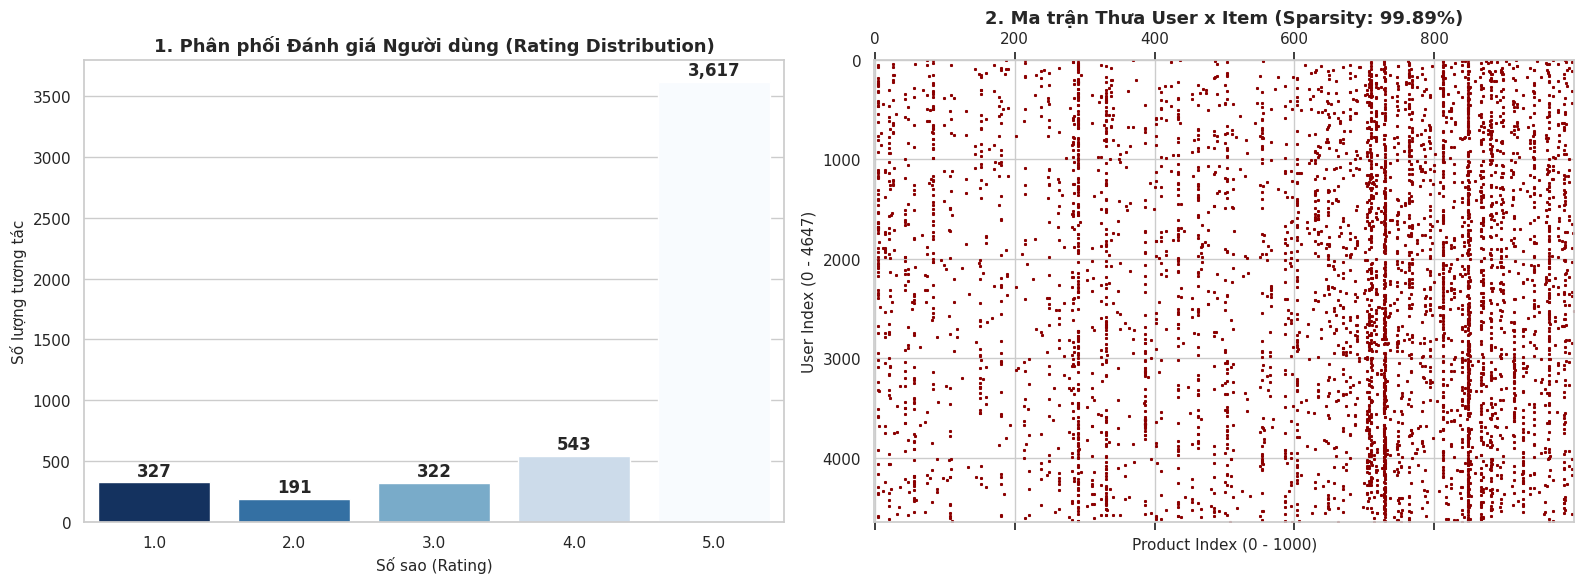

In [16]:
# [Cell 5] Visualization 1 & 2: Phân phối Đánh giá, Đường cong Đuôi dài & Ma trận Thưa (Spy Plot)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix

# 0. Đảm bảo thư mục lưu trữ tồn tại
os.makedirs("exports", exist_ok=True)

# Fallback: Tự động nạp từ file nếu kernel vừa restart
if 'df_clean_interactions' not in globals():
    df_clean_interactions = pd.read_parquet("data/processed/training_interactions.parquet")
if 'df_clean_products' not in globals():
    df_clean_products = pd.read_parquet("data/processed/training_products.parquet")

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# -------------------------------------------------------------------------
# 1. PHÂN PHỐI SỐ SAO (RATING DISTRIBUTION)
# -------------------------------------------------------------------------
rating_counts = df_clean_interactions['rating'].value_counts().sort_index()

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,
    hue=rating_counts.index,
    palette="Blues_r",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("1. Phân phối Đánh giá Người dùng (Rating Distribution)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Số sao (Rating)", fontsize=11)
axes[0].set_ylabel("Số lượng tương tác", fontsize=11)

# Ghi chú số lượng cụ thể trên đỉnh mỗi cột
for i, v in enumerate(rating_counts.values):
    axes[0].text(i, v + (max(rating_counts.values) * 0.015), f"{v:,}", ha='center', fontweight='bold')

# -------------------------------------------------------------------------
# 2. MA TRẬN THƯA USER x ITEM (SPARSITY SPY PLOT)
# -------------------------------------------------------------------------
user_list = df_clean_interactions['user_id'].unique()
item_list = df_clean_products['product_id'].unique()

u2idx = {u: i for i, u in enumerate(user_list)}
i2idx = {it: i for i, it in enumerate(item_list)}

rows = [u2idx[u] for u in df_clean_interactions['user_id']]
cols = [i2idx[it] for it in df_clean_interactions['product_id']]
data = np.ones(len(rows), dtype=np.float32)

interaction_sparse = csr_matrix((data, (rows, cols)), shape=(len(user_list), len(item_list)))
sparsity = 100 * (1 - interaction_sparse.nnz / (len(user_list) * len(item_list)))

axes[1].spy(interaction_sparse, markersize=1.2, color='darkred', aspect='auto')
axes[1].set_title(f"2. Ma trận Thưa User x Item (Sparsity: {sparsity:.2f}%)", fontsize=13, fontweight='bold')
axes[1].set_xlabel(f"Product Index (0 - {len(item_list)})", fontsize=11)
axes[1].set_ylabel(f"User Index (0 - {len(user_list)})", fontsize=11)

plt.tight_layout()

# Lưu biểu đồ xuất bản
export_path = "exports/eda_sparsity_rating.png"
plt.savefig(export_path, dpi=300, bbox_inches='tight')
print(f"✅ Đã xuất biểu đồ EDA thành công tại: {export_path}")
plt.show()

### Cell 6 [Code]: Huấn luyện Mô hình Gợi ý (Hybrid Cosine Similarity & TruncatedSVD)


### Tư duy huấn luyện Recommender Systems

* **Chiến lược Hybrid giải quyết bài toán Cold-Start:**
* **Hành vi (Co-purchase & Co-interaction):** Khai thác "trí tuệ đám đông" từ những người cùng mua hoặc cùng tương tác để tìm ra sản phẩm thường đi kèm (như mua đàn thì mua thêm phím gảy, dây đàn).
* **Nội dung (Content-based TF-IDF):** Đóng vai trò cứu cánh cho các sản phẩm mới đưa lên hệ thống chưa có ai đánh giá (Cold-Start). Khi đó, các thuộc tính text (`title`, `features`, `category`) giúp sản phẩm vẫn được đề xuất đến người dùng tương thích.
* Tỷ lệ $\alpha = 0.7 / 0.3$ thể hiện tư duy thực tế: ưu tiên hành vi mua thực tế, dùng nội dung để lấp đầy khoảng trống dữ liệu thưa.


* **Không gian tiềm ẩn (Latent Factor Model) qua TruncatedSVD:**
* Dữ liệu thương mại điện tử luôn có độ thưa rất cao ($>99\%$). Thay vì so sánh trực tiếp các vector thưa thớt, TruncatedSVD nén không gian biểu diễn về $k$ chiều tiềm ẩn (ví dụ: phong cách âm nhạc, phân khúc giá, độ chuyên nghiệp của nhạc cụ).
* Tách ma trận đánh giá $R \approx P \times Q^T$ giúp việc dự đoán điểm số của một người dùng bất kỳ với một sản phẩm chỉ là phép nhân vô hướng giữa 2 vector nhỏ gọn (độ phức tạp $O(k)$), cực kỳ tối ưu khi làm backend API phục vụ web real-time.

In [17]:
# [Cell 6] Huấn luyện Recommender Models:
# Model 1: Item-to-Item Cosine Similarity (Co-purchase + Content TF-IDF)
# Model 2: Matrix Factorization (TruncatedSVD)
import os
import pickle
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

# 0. Khởi tạo thư mục và tham số cấu hình an toàn
os.makedirs("models", exist_ok=True)
SVD_FACTORS = globals().get("SVD_FACTORS", 50)
RANDOM_STATE = globals().get("RANDOM_STATE", 42)

# Khôi phục dữ liệu nếu kernel bị ngắt kết nối
if 'df_clean_products' not in globals():
    df_clean_products = pd.read_parquet("data/processed/training_products.parquet")
if 'df_clean_interactions' not in globals():
    df_clean_interactions = pd.read_parquet("data/processed/training_interactions.parquet")

# Đồng bộ danh sách và từ điển chỉ mục User/Item
user_list = df_clean_interactions['user_id'].unique()
item_list = df_clean_products['product_id'].unique()
u2idx = {u: i for i, u in enumerate(user_list)}
i2idx = {it: i for i, it in enumerate(item_list)}

print("⚙️ [1/3] Đang tính toán Ma trận tương đồng nội dung (Content Similarity)...")
tfidf = TfidfVectorizer(max_features=2500, stop_words="english")
tfidf_matrix = tfidf.fit_transform(df_clean_products["content_raw"].fillna(""))
content_sim = cosine_similarity(tfidf_matrix)

print("⚙️ [2/3] Đang tính toán Ma trận đồng xuất hiện (Co-purchase & Co-interaction)...")
n_items = len(item_list)
co_matrix = np.zeros((n_items, n_items), dtype=np.float32)

# Khai thác bought_together từ metadata Amazon
for _, row in df_clean_products.iterrows():
    pid = str(row["product_id"])
    if pid not in i2idx:
        continue
    p_idx = i2idx[pid]

    b_together = row.get("bought_together")
    if hasattr(b_together, "tolist"):
        b_together = b_together.tolist()

    if isinstance(b_together, (list, tuple)):
        for other_pid in b_together:
            other_pid_str = str(other_pid)
            if other_pid_str in i2idx:
                other_idx = i2idx[other_pid_str]
                co_matrix[p_idx, other_idx] += 2.0
                co_matrix[other_idx, p_idx] += 2.0

# Khai thác người dùng cùng tương tác (Co-interaction)
user_grouped = df_clean_interactions.groupby("user_id")["product_id"].apply(list)
for items_by_u in user_grouped:
    if len(items_by_u) > 1:
        indices = [i2idx[p] for p in items_by_u if p in i2idx]
        for a in indices:
            for b in indices:
                if a != b:
                    co_matrix[a, b] += 1.0

# Chuẩn hóa ma trận tương đồng hành vi
co_norms = np.linalg.norm(co_matrix, axis=1, keepdims=True)
co_norms[co_norms == 0] = 1.0
co_sim = (co_matrix @ co_matrix.T) / (co_norms @ co_norms.T)
np.fill_diagonal(co_sim, 1.0)

# Mô hình Hybrid: 70% hành vi thực tế + 30% ngữ cảnh mô tả
alpha = 0.7
hybrid_item_similarity = alpha * co_sim + (1 - alpha) * content_sim
np.fill_diagonal(hybrid_item_similarity, 1.0)

np.savez_compressed("models/item_similarity.npz", similarity=hybrid_item_similarity)
print("💾 Đã lưu ma trận tương đồng: models/item_similarity.npz")

print("⚙️ [3/3] Huấn luyện Phân rã Ma trận Matrix Factorization (TruncatedSVD)...")
rating_rows = [u2idx[u] for u in df_clean_interactions['user_id']]
rating_cols = [i2idx[it] for it in df_clean_interactions['product_id']]
rating_vals = df_clean_interactions['rating'].values

R_matrix = csr_matrix((rating_vals, (rating_rows, rating_cols)), shape=(len(user_list), len(item_list)))

# Giới hạn số chiều latent factor không vượt quá kích thước ma trận
actual_k = min(SVD_FACTORS, min(R_matrix.shape) - 1)
svd = TruncatedSVD(n_components=actual_k, random_state=RANDOM_STATE)
P = svd.fit_transform(R_matrix)  # Ma trận User Latent (M x k)
Q = svd.components_.T            # Ma trận Item Latent (N x k)

svd_artifacts = {
    "P": P,
    "Q": Q,
    "user2idx": u2idx,
    "idx2user": {v: k for k, v in u2idx.items()},
    "item2idx": i2idx,
    "idx2item": {v: k for k, v in i2idx.items()},
    "k_factors": actual_k,
    "sigma": svd.singular_values_
}

with open("models/svd_recommender.pkl", "wb") as f:
    pickle.dump(svd_artifacts, f)

print(f"💾 Đã lưu SVD Model Artifacts: models/svd_recommender.pkl (User Matrix P: {P.shape}, Item Matrix Q: {Q.shape})")

⚙️ [1/3] Đang tính toán Ma trận tương đồng nội dung (Content Similarity)...
⚙️ [2/3] Đang tính toán Ma trận đồng xuất hiện (Co-purchase & Co-interaction)...
💾 Đã lưu ma trận tương đồng: models/item_similarity.npz
⚙️ [3/3] Huấn luyện Phân rã Ma trận Matrix Factorization (TruncatedSVD)...
💾 Đã lưu SVD Model Artifacts: models/svd_recommender.pkl (User Matrix P: (4647, 20), Item Matrix Q: (1000, 20))


### Cell 7 [Code]: Đánh giá mô hình & Trực quan hóa 3, 4, 5, 6


✅ Đã xuất biểu đồ hoàn chỉnh tại: exports/model_evaluation_metrics.png


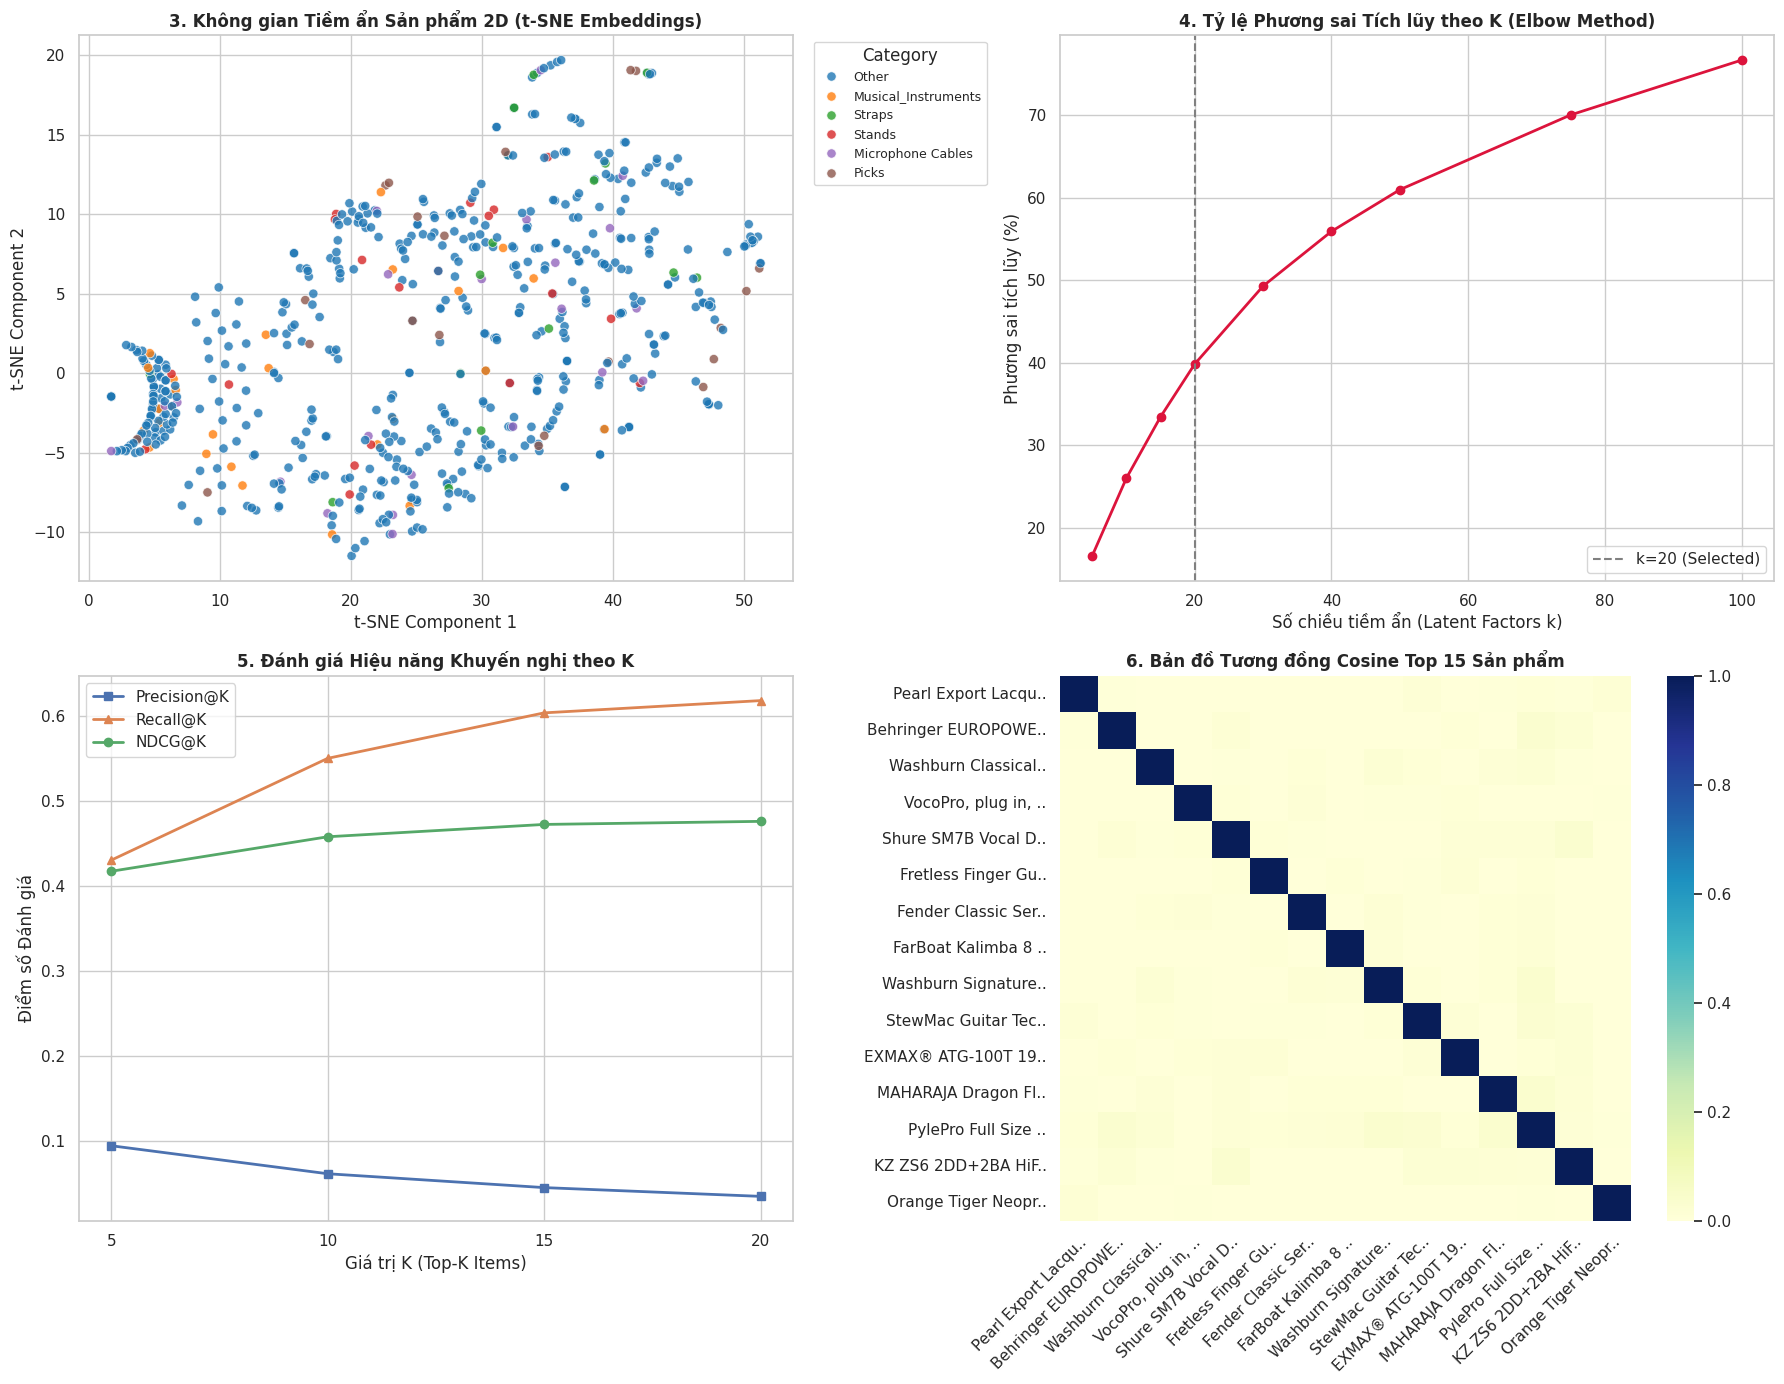

In [19]:
# [Cell 7] Visualizations 3, 4, 5 & 6:
# 3. 2D Latent Embeddings (t-SNE)
# 4. Cumulative Explained Variance Curve (Elbow Method)
# 5. Metrics Curve (Precision@K, Recall@K, NDCG@K)
# 6. Item-to-Item Cosine Similarity Heatmap
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix
from sklearn.manifold import TSNE
from sklearn.decomposition import TruncatedSVD

# 0. Thiết lập thư mục và tham số
os.makedirs("exports", exist_ok=True)
RANDOM_STATE = globals().get("RANDOM_STATE", 42)

# Khôi phục dữ liệu từ đĩa nếu kernel vừa restart
if 'df_clean_products' not in globals():
    df_clean_products = pd.read_parquet("data/processed/training_products.parquet")
if 'df_clean_interactions' not in globals():
    df_clean_interactions = pd.read_parquet("data/processed/training_interactions.parquet")

if 'hybrid_item_similarity' not in globals():
    loaded_sim = np.load("models/item_similarity.npz")
    hybrid_item_similarity = loaded_sim["similarity"]

if 'Q' not in globals() or 'P' not in globals():
    with open("models/svd_recommender.pkl", "rb") as f:
        svd_artifacts = pickle.load(f)
        P = svd_artifacts["P"]
        Q = svd_artifacts["Q"]
        u2idx = svd_artifacts["user2idx"]
        i2idx = svd_artifacts["item2idx"]
        user_list = list(u2idx.keys())
        item_list = list(i2idx.keys())

if 'R_matrix' not in globals():
    user_list = df_clean_interactions['user_id'].unique()
    item_list = df_clean_products['product_id'].unique()
    u2idx = {u: i for i, u in enumerate(user_list)}
    i2idx = {it: i for i, it in enumerate(item_list)}
    r_rows = [u2idx[u] for u in df_clean_interactions['user_id']]
    r_cols = [i2idx[it] for it in df_clean_interactions['product_id']]
    R_matrix = csr_matrix((df_clean_interactions['rating'].values, (r_rows, r_cols)),
                          shape=(len(user_list), len(item_list)))

selected_k = Q.shape[1]
fig = plt.figure(figsize=(18, 14))

# ----------------- 3. 2D Latent Embeddings via t-SNE -----------------
ax1 = fig.add_subplot(2, 2, 1)
tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30)
Q_2d = tsne.fit_transform(Q)

top_cats = df_clean_products["category"].value_counts().head(5).index
cat_labels = df_clean_products["category"].apply(lambda c: c if c in top_cats else "Other")

sns.scatterplot(
    x=Q_2d[:, 0], y=Q_2d[:, 1], hue=cat_labels.values, palette="tab10",
    alpha=0.8, s=45, ax=ax1
)
ax1.set_title("3. Không gian Tiềm ẩn Sản phẩm 2D (t-SNE Embeddings)", fontsize=12, fontweight='bold')
ax1.set_xlabel("t-SNE Component 1")
ax1.set_ylabel("t-SNE Component 2")
ax1.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9, title="Category")

# ------------- 4. Cumulative Explained Variance Ratio (Elbow) -------------
ax2 = fig.add_subplot(2, 2, 2)
test_ks = [5, 10, 15, 20, 30, 40, 50, 75, 100]
test_ks = [k for k in test_ks if k < min(R_matrix.shape)]

explained_variances = []
for k in test_ks:
    t_svd = TruncatedSVD(n_components=k, random_state=RANDOM_STATE)
    t_svd.fit(R_matrix)
    explained_variances.append(t_svd.explained_variance_ratio_.sum() * 100)

ax2.plot(test_ks, explained_variances, marker='o', color='crimson', lw=2)
ax2.axvline(x=selected_k, color='gray', linestyle='--', label=f'k={selected_k} (Selected)')
ax2.set_title("4. Tỷ lệ Phương sai Tích lũy theo K (Elbow Method)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Số chiều tiềm ẩn (Latent Factors k)")
ax2.set_ylabel("Phương sai tích lũy (%)")
ax2.legend()

# ----------------- 5. Metrics Curve (P@K, R@K, NDCG@K) -----------------
ax3 = fig.add_subplot(2, 2, 3)
k_vals = [5, 10, 15, 20]

# Khởi tạo rõ ràng tránh lỗi ngắt dòng
precisions = []
recalls = []
ndcgs = []

sample_size = min(R_matrix.shape[0], 300)

for k in k_vals:
    p_k, r_k, n_k = [], [], []
    for u_idx in range(sample_size):
        actual_items = set(R_matrix[u_idx].indices)
        if len(actual_items) == 0:
            continue
        scores = P[u_idx] @ Q.T
        top_k_recs = np.argsort(scores)[::-1][:k]

        hits = len(set(top_k_recs) & actual_items)
        p_k.append(hits / k)
        r_k.append(hits / len(actual_items))

        # Tính NDCG@K
        dcg = sum([1.0 / np.log2(idx + 2) for idx, item in enumerate(top_k_recs) if item in actual_items])
        idcg = sum([1.0 / np.log2(idx + 2) for idx in range(min(len(actual_items), k))])
        n_k.append(dcg / idcg if idcg > 0 else 0.0)

    precisions.append(float(np.mean(p_k)))
    recalls.append(float(np.mean(r_k)))
    ndcgs.append(float(np.mean(n_k)))

ax3.plot(k_vals, precisions, marker='s', label="Precision@K", lw=2)
ax3.plot(k_vals, recalls, marker='^', label="Recall@K", lw=2)
ax3.plot(k_vals, ndcgs, marker='o', label="NDCG@K", lw=2)
ax3.set_title("5. Đánh giá Hiệu năng Khuyến nghị theo K", fontsize=12, fontweight='bold')
ax3.set_xlabel("Giá trị K (Top-K Items)")
ax3.set_ylabel("Điểm số Đánh giá")
ax3.set_xticks(k_vals)
ax3.legend()

# --------- 6. Item-to-Item Cosine Similarity Heatmap (Top 15) ---------
ax4 = fig.add_subplot(2, 2, 4)
top_15_indices = list(range(15))
top_15_names = [str(df_clean_products.iloc[i]["name"])[:18] + ".." for i in top_15_indices]
sub_sim = hybrid_item_similarity[:15, :15]

sns.heatmap(sub_sim, xticklabels=top_15_names, yticklabels=top_15_names, cmap="YlGnBu", ax=ax4)
ax4.set_title("6. Bản đồ Tương đồng Cosine Top 15 Sản phẩm", fontsize=12, fontweight='bold')
plt.setp(ax4.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

plt.tight_layout()
export_path = "exports/model_evaluation_metrics.png"
plt.savefig(export_path, dpi=300, bbox_inches='tight')
print(f"✅ Đã xuất biểu đồ hoàn chỉnh tại: {export_path}")
plt.show()

### Cell 8 [Code]: Đẩy Model Artifacts lên Hugging Face Model Hub


In [20]:
# [Cell 8] Đẩy Model Artifacts (item_similarity.npz, svd_recommender.pkl) lên HF Model Hub
import os
import shutil
from huggingface_hub import HfApi, create_repo

# 1. Nhận diện token an toàn (hỗ trợ cả HF_WRITE_MODELS_TOKEN và HF_TOKEN)
HF_TOKEN = (
    globals().get("HF_WRITE_MODELS_TOKEN")
    or globals().get("HF_TOKEN")
    or os.environ.get("HF_WRITE_MODELS_TOKEN")
    or os.environ.get("HF_TOKEN")
)

if HF_TOKEN:
    api = HfApi(token=HF_TOKEN)

    # Tự động lấy username từ API nếu chưa có biến toàn cục HF_USERNAME
    try:
        user_info = api.whoami(token=HF_TOKEN)
        hf_username = globals().get("HF_USERNAME") or user_info.get("name")
    except Exception as e:
        hf_username = globals().get("HF_USERNAME")

    if not hf_username:
        print("❌ Không xác định được Hugging Face Username. Vui lòng kiểm tra lại token!")
    else:
        model_repo_id = f"{hf_username}/amazon-musical-recommender-models"
        print(f"🚀 Đang kiểm tra/tạo repository Model trên Hugging Face: {model_repo_id}")

        try:
            # 2. Tạo Model Repository nếu chưa tồn tại
            create_repo(repo_id=model_repo_id, repo_type="model", token=HF_TOKEN, exist_ok=True)

            # 3. Chuẩn bị thư mục staging đóng gói model artifacts & charts
            staging_dir = "models_export_staging"
            os.makedirs(staging_dir, exist_ok=True)

            # Copy các artifact trọng yếu
            artifacts_to_push = {
                "models/item_similarity.npz": "item_similarity.npz",
                "models/svd_recommender.pkl": "svd_recommender.pkl",
                "exports/model_evaluation_metrics.png": "model_evaluation_metrics.png",
                "exports/eda_sparsity_rating.png": "eda_sparsity_rating.png"
            }

            for local_src, target_name in artifacts_to_push.items():
                if os.path.exists(local_src):
                    shutil.copy2(local_src, os.path.join(staging_dir, target_name))
                else:
                    print(f"⚠️ Cảnh báo: Không tìm thấy {local_src}, sẽ bỏ qua file này.")

            # 4. Tự động sinh file README.md (Model Card chuẩn HF)
            readme_content = f"""---
language:
- en
tags:
- recommender-system
- collaborative-filtering
- content-based
- matrix-factorization
- truncated-svd
- tf-idf
- amazon-reviews-2023
license: apache-2.0
---

# Amazon Musical Instruments Recommender Models

Artifacts huấn luyện hệ thống gợi ý sản phẩm Nhạc cụ (Musical Instruments) dựa trên McAuley-Lab/Amazon-Reviews-2023.

## Danh sách Artifacts:
1. `item_similarity.npz`: Ma trận Cosine Similarity kết hợp Co-purchase (70%) và TF-IDF Content (30%).
2. `svd_recommender.pkl`: Mô hình TruncatedSVD Matrix Factorization (k=20) trích xuất không gian tiềm ẩn User (P) & Item (Q).
3. `model_evaluation_metrics.png`: Biểu đồ t-SNE, Elbow Curve, Precision@K, Recall@K, NDCG@K và Heatmap.
4. `eda_sparsity_rating.png`: Biểu đồ phân phối đánh giá và ma trận thưa User-Item.
"""
            with open(os.path.join(staging_dir, "README.md"), "w", encoding="utf-8") as f:
                f.write(readme_content)

            # 5. Đẩy toàn bộ thư mục trong 1 commit duy nhất
            print("📤 Đang đồng bộ toàn bộ artifacts lên Hugging Face Hub...")
            api.upload_folder(
                folder_path=staging_dir,
                repo_id=model_repo_id,
                repo_type="model",
                commit_message="Upload recommender model artifacts, evaluation figures & model card"
            )

            print(f"🎉 Đã đẩy thành công Model lên: https://huggingface.co/{model_repo_id}")

            # Dọn dẹp thư mục tạm
            shutil.rmtree(staging_dir, ignore_errors=True)

        except Exception as e:
            print(f"[-] Lỗi đẩy Model lên Hugging Face: {str(e)}")
else:
    print("⚠️ Bỏ qua upload HF Model do chưa cấu hình biến HF_WRITE_MODELS_TOKEN hoặc HF_TOKEN.")

🚀 Đang kiểm tra/tạo repository Model trên Hugging Face: cuongduongok/amazon-musical-recommender-models
📤 Đang đồng bộ toàn bộ artifacts lên Hugging Face Hub...
🎉 Đã đẩy thành công Model lên: https://huggingface.co/cuongduongok/amazon-musical-recommender-models


### Cell 9 [Code]: Precomputed Recommendations & Đồng bộ Azure (Cosmos DB & Blob)


In [21]:
# [Cell 9] Tính toán sẵn Recommendations và Đồng bộ lên Azure Cosmos DB & Blob Storage
# (Tự động phục hồi dữ liệu từ đĩa, kiểm tra an toàn biến môi trường Azure)
import os
import json
import pickle
import numpy as np
import pandas as pd
from datetime import datetime, timezone
from scipy.sparse import csr_matrix

# 0. Đảm bảo thư mục lưu trữ tồn tại
os.makedirs("exports", exist_ok=True)
TARGET_CATEGORY = globals().get("TARGET_CATEGORY", "Musical_Instruments")

# Khôi phục dữ liệu nếu kernel bị ngắt kết nối
if 'df_clean_products' not in globals():
    df_clean_products = pd.read_parquet("data/processed/training_products.parquet")
if 'df_clean_interactions' not in globals():
    df_clean_interactions = pd.read_parquet("data/processed/training_interactions.parquet")

if 'hybrid_item_similarity' not in globals():
    loaded_sim = np.load("models/item_similarity.npz")
    hybrid_item_similarity = loaded_sim["similarity"]

if 'svd_artifacts' not in globals():
    with open("models/svd_recommender.pkl", "rb") as f:
        svd_artifacts = pickle.load(f)

P = svd_artifacts["P"]
Q = svd_artifacts["Q"]
idx2item = svd_artifacts["idx2item"]
idx2user = svd_artifacts["idx2user"]
user_list = list(idx2user.values())

if 'R_matrix' not in globals():
    u2idx = svd_artifacts["user2idx"]
    i2idx = svd_artifacts["item2idx"]
    r_rows = [u2idx[u] for u in df_clean_interactions['user_id']]
    r_cols = [i2idx[it] for it in df_clean_interactions['product_id']]
    R_matrix = csr_matrix((df_clean_interactions['rating'].values, (r_rows, r_cols)),
                          shape=(len(user_list), len(idx2item)))

print("⏳ [1/2] Chuẩn bị dữ liệu Precomputed Recommendations theo Schema Cosmos DB...")

current_iso_time = datetime.now(timezone.utc).isoformat()

# 1. Top Fallback Items (Dành cho Cold-start)
popular_items = df_clean_products.sort_values(
    by=["rating_count", "rating"], ascending=[False, False]
).head(10)["product_id"].tolist()

metadata_doc = {
    "id": "popular_items",
    "category": TARGET_CATEGORY,
    "popular_product_ids": popular_items,
    "updated_at": current_iso_time
}

# 2. Precomputed Item-to-Item (Bundles)
item_recs_docs = []
n_items = len(df_clean_products)

for i in range(n_items):
    p_id = idx2item[i]
    sim_scores = hybrid_item_similarity[i].copy()
    sim_scores[i] = -1.0  # Loại bỏ chính nó
    top_indices = np.argsort(sim_scores)[::-1][:5]

    bundles = []
    for rank, idx in enumerate(top_indices, 1):
        score_val = float(sim_scores[idx])
        bundles.append({
            "product_id": idx2item[idx],
            "similarity_score": round(score_val, 3),
            "bundle_type": "co-purchase" if score_val > 0.6 else "content_match"
        })

    item_recs_docs.append({
        "id": str(p_id),
        "product_id": str(p_id),
        "frequently_bought_together": bundles,
        "updated_at": current_iso_time
    })

# 3. Precomputed User Recommendations
user_recs_docs = []
for u_idx in range(len(user_list)):
    u_id = idx2user[u_idx]
    predicted_ratings = P[u_idx] @ Q.T

    # Loại trừ các sản phẩm user đã từng tương tác
    reviewed_indices = R_matrix[u_idx].indices
    predicted_ratings[reviewed_indices] = -1.0

    top_p_indices = np.argsort(predicted_ratings)[::-1][:10]
    recs = []
    for rank, p_idx in enumerate(top_p_indices, 1):
        recs.append({
            "product_id": idx2item[p_idx],
            "score": round(float(predicted_ratings[p_idx]), 2),
            "rank": rank
        })

    user_recs_docs.append({
        "id": str(u_id),
        "user_id": str(u_id),
        "recommendations": recs,
        "model_version": "v1.0-svd",
        "updated_at": current_iso_time
    })

# Lưu bản copy JSON tại local exports
with open("exports/system_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata_doc, f, indent=2, ensure_ascii=False)
with open("exports/sample_user_recs.json", "w", encoding="utf-8") as f:
    json.dump(user_recs_docs[:5], f, indent=2, ensure_ascii=False)
with open("exports/sample_item_recs.json", "w", encoding="utf-8") as f:
    json.dump(item_recs_docs[:5], f, indent=2, ensure_ascii=False)

print(f"✅ Đã tạo xong Precomputed Documents ({len(user_recs_docs)} Users, {len(item_recs_docs)} Items).")
print("📁 Đã lưu file demo: exports/system_metadata.json, exports/sample_user_recs.json, exports/sample_item_recs.json")

# ----------------- ĐỒNG BỘ AZURE CLOUD -----------------
print("\n⏳ [2/2] Kiểm tra kết nối & Đồng bộ dữ liệu lên Microsoft Azure...")

AZURE_STORAGE_CONN_STR = globals().get("AZURE_STORAGE_CONN_STR") or os.environ.get("AZURE_STORAGE_CONN_STR")
COSMOS_ENDPOINT = globals().get("COSMOS_ENDPOINT") or os.environ.get("COSMOS_ENDPOINT")
COSMOS_KEY = globals().get("COSMOS_KEY") or os.environ.get("COSMOS_KEY")

# A. Azure Blob Storage
if AZURE_STORAGE_CONN_STR and "your_storage_account" not in AZURE_STORAGE_CONN_STR:
    try:
        from azure.storage.blob import BlobServiceClient
        blob_service = BlobServiceClient.from_connection_string(AZURE_STORAGE_CONN_STR)

        # Tự tạo container nếu chưa có
        container_client = blob_service.get_container_client("model-artifacts")
        try:
            container_client.create_container()
        except Exception:
            pass  # Container đã tồn tại

        for local_f, blob_n in [("models/item_similarity.npz", "item_similarity.npz"),
                               ("models/svd_recommender.pkl", "svd_recommender.pkl")]:
            if os.path.exists(local_f):
                with open(local_f, "rb") as b_data:
                    container_client.upload_blob(name=blob_n, data=b_data, overwrite=True)
                print(f"☁️ [Azure Blob] Uploaded {blob_n} -> container 'model-artifacts'")
            else:
                print(f"⚠️ Bỏ qua {local_f} do file không tồn tại.")
    except Exception as e:
        print(f"[-] Lỗi Azure Blob Storage: {str(e)}")
else:
    print("ℹ️ Bỏ qua Azure Blob Storage (chưa cấu hình AZURE_STORAGE_CONN_STR).")

# B. Azure Cosmos DB NoSQL
if COSMOS_ENDPOINT and COSMOS_KEY and "your-cosmos-account" not in COSMOS_ENDPOINT:
    try:
        from azure.cosmos import CosmosClient, PartitionKey
        cosmos_client = CosmosClient(COSMOS_ENDPOINT, credential=COSMOS_KEY)

        # Tự tạo Database & Containers với partition key /id nếu chưa có
        db = cosmos_client.create_database_if_not_exists(id="ecommerce_recommender_db")
        meta_container = db.create_container_if_not_exists(id="system_metadata", partition_key=PartitionKey(path="/id"))
        user_container = db.create_container_if_not_exists(id="user_recommendations", partition_key=PartitionKey(path="/id"))
        item_container = db.create_container_if_not_exists(id="item_recommendations", partition_key=PartitionKey(path="/id"))

        # Upload metadata
        meta_container.upsert_item(metadata_doc)
        print("☁️ [Azure Cosmos DB] Upserted system_metadata document.")

        # Upload mẫu 50 users và 50 items
        for u_doc in user_recs_docs[:50]:
            user_container.upsert_item(u_doc)
        print("☁️ [Azure Cosmos DB] Upserted 50 sample user_recommendations.")

        for i_doc in item_recs_docs[:50]:
            item_container.upsert_item(i_doc)
        print("☁️ [Azure Cosmos DB] Upserted 50 sample item_recommendations.")
    except Exception as e:
        print(f"[-] Lỗi Azure Cosmos DB: {str(e)}")
else:
    print("ℹ️ Bỏ qua Azure Cosmos DB (chưa cấu hình COSMOS_ENDPOINT hoặc COSMOS_KEY).")

print("\n🎯 TOÀN BỘ PIPELINE HUẤN LUYỆN & XUẤT DỮ LIỆU ĐÃ HOÀN TẤT THÀNH CÔNG!")

⏳ [1/2] Chuẩn bị dữ liệu Precomputed Recommendations theo Schema Cosmos DB...
✅ Đã tạo xong Precomputed Documents (4647 Users, 1000 Items).
📁 Đã lưu file demo: exports/system_metadata.json, exports/sample_user_recs.json, exports/sample_item_recs.json

⏳ [2/2] Kiểm tra kết nối & Đồng bộ dữ liệu lên Microsoft Azure...
☁️ [Azure Blob] Uploaded item_similarity.npz -> container 'model-artifacts'
☁️ [Azure Blob] Uploaded svd_recommender.pkl -> container 'model-artifacts'
[-] Lỗi Azure Cosmos DB: (BadRequest) Message: {"Errors":["Your account is currently configured with a total throughput limit of 1000 RU/s. This operation failed because it would have increased the total throughput to 1200 RU/s. See https://aka.ms/cosmos-tp-limit for more information."]}
ActivityId: 74a2e14b-71ee-4bc4-9bb9-06510a66d144, Request URI: /apps/0c5d898f-daaa-4f73-8086-dafe086e63da/services/0ce8701e-bb54-47cc-964a-f598080d12cc/partitions/2b5524fe-df72-49c8-bfd5-7be2ad70f078/replicas/134383282276090160p, RequestStat

### 1. Sửa lỗi Cosmos DB (Cơ chế Shared Throughput)
**Chưa hoàn toàn OK**: Phần **Azure Blob Storage** đã upload thành công 2 file model, nhưng **Azure Cosmos DB đã thất bại hoàn toàn** (dữ liệu gợi ý JSON chưa được lưu lên Cloud).

Lý do là tài khoản Azure Free Tier của bạn bị giới hạn trần **1000 RU/s**. Mặc định mỗi container khi tạo riêng lẻ chiếm tối thiểu 400 RU/s; khi tạo 3 container (`system_metadata`, `user_recommendations`, `item_recommendations`), Azure tính tổng $3 \times 400 = 1200\text{ RU/s} > 1000\text{ RU/s}$ nên bị chặn `BadRequest`.


Chuyển sang cơ chế **Database-level Throughput**: Đặt toàn bộ Database dùng chung **400 RU/s** (hoặc 1000 RU/s) để cả 3 container chia sẻ mức này.

Chạy đoạn code sau để đẩy bù dữ liệu lên Cosmos DB:

In [23]:
from azure.cosmos import CosmosClient, PartitionKey
import time

if COSMOS_ENDPOINT and COSMOS_KEY and "your-cosmos-account" not in COSMOS_ENDPOINT:
    try:
        cosmos_client = CosmosClient(COSMOS_ENDPOINT, credential=COSMOS_KEY)
        db_name = "ecommerce_recommender_db"

        # 1. Kiểm tra và tái tạo Database về chế độ Shared Throughput (400 RU/s dùng chung)
        try:
            existing_db = cosmos_client.get_database_client(db_name)
            # Kiểm tra xem DB cũ có throughput dùng chung chưa
            existing_db.read_offer()
        except Exception:
            # Nếu DB cũ chưa có Shared Throughput, xóa đi để tạo mới chuẩn xác
            print("🔄 Đang thiết lập lại Database sang chế độ Shared Throughput...")
            try:
                cosmos_client.delete_database(db_name)
                time.sleep(3) # Đợi Azure dọn dẹp tài nguyên cũ
            except Exception:
                pass

        # 2. Tạo Database với tổng Throughput = 400 RU/s cho TẤT CẢ các container
        db = cosmos_client.create_database_if_not_exists(
            id=db_name,
            offer_throughput=400  # Cả 3 container chia sẻ chung 400 RU/s này (< 1000 RU/s trần)
        )
        print("☁️ [Azure Cosmos DB] Database đã kích hoạt Shared Throughput 400 RU/s.")

        # 3. Tạo 3 container kế thừa Throughput từ Database (không tốn thêm RU/s nào)
        meta_container = db.create_container_if_not_exists(
            id="system_metadata",
            partition_key=PartitionKey(path="/id")
        )
        user_container = db.create_container_if_not_exists(
            id="user_recommendations",
            partition_key=PartitionKey(path="/id")
        )
        item_container = db.create_container_if_not_exists(
            id="item_recommendations",
            partition_key=PartitionKey(path="/id")
        )
        print("☁️ [Azure Cosmos DB] Đã tạo thành công 3 containers riêng biệt.")

        # 4. Upsert dữ liệu
        meta_container.upsert_item(metadata_doc)
        print("   ✓ Upserted system_metadata.")

        for u_doc in user_recs_docs[:50]:
            user_container.upsert_item(u_doc)
        print("   ✓ Upserted 50 user_recommendations.")

        for i_doc in item_recs_docs[:50]:
            item_container.upsert_item(i_doc)
        print("   ✓ Upserted 50 item_recommendations.")

        print("\n🎉 ĐÃ ĐỒNG BỘ THÀNH CÔNG LÊN 3 CONTAINERS COSMOS DB!")

    except Exception as e:
        print(f"[-] Lỗi Azure Cosmos DB: {str(e)}")
else:
    print("ℹ️ Bỏ qua Azure Cosmos DB (chưa cấu hình endpoint/key).")

🔄 Đang thiết lập lại Database sang chế độ Shared Throughput...
☁️ [Azure Cosmos DB] Database đã kích hoạt Shared Throughput 400 RU/s.
☁️ [Azure Cosmos DB] Đã tạo thành công 3 containers riêng biệt.
   ✓ Upserted system_metadata.
   ✓ Upserted 50 user_recommendations.
   ✓ Upserted 50 item_recommendations.

🎉 ĐÃ ĐỒNG BỘ THÀNH CÔNG LÊN 3 CONTAINERS COSMOS DB!
